# First Deep Learning Project in Python with Keras

The steps we are going to cover:
1. Load Data.
2. Define Keras Model.
3. Compile Keras Model.
4. Fit Keras Model.
5. Evaluate Keras Model.
6. Put It All Together.
7. Make Predictions

## Load Data
    

Download the dataset and place it in your local working directory, the same location as your python file. Take a look at the dataset:

In [1]:
import pandas as pd
df = pd.read_csv('../Data/housepricedata.csv')

Here, you can explore the data a little. We have our input features in the first ten columns:

- Lot Area (in sq ft)
- Overall Quality (scale from 1 to 10)
- Overall Condition (scale from 1 to 10)
- Total Basement Area (in sq ft)
- Number of Full Bathrooms
- Number of Half Bathrooms
- Number of Bedrooms above ground
- Total Number of Rooms above ground
- Number of Fireplaces
- Garage Area (in sq ft)

In our last column, we have the feature that we would like to predict:
- Is the house price above the median or not? (1 for yes and 0 for no)

Which task are we going to train the neural network for (regression, classification, other...) ?

In [2]:
# Your answer here : 

Now that we’ve seen what our data looks like, we want to convert it into arrays for our machine to process:

In [3]:
dataset = df.values

Split the dataset into input features (X) and the feature we wish to predict (Y). To do that split, assign the first 10 columns of our array to a variable called X and the last column of our array to a variable called Y

In [4]:
X = dataset[:,0:10]
y = dataset[:,10]

Now, we want to split our dataset into a training set, a validation set and a test set. These are the dimensions you need to get for your train, validation and test datasets: (1022, 10) (219, 10) (219, 10) (1022,) (219,) (219,)

We will use the code from scikit-learn called ‘train_test_split’, which as the name suggests, split our dataset into a training set and a test set. We first import the code we need:

In [9]:
# splitting into train and test

from sklearn.model_selection import train_test_split
X_train, X_val_and_test, Y_train, Y_val_and_test = train_test_split(X, y, test_size=0.3, random_state=42)

Unfortunately, this function only helps us split our dataset into two. Since we want a separate validation set and test set, we can use the same function to do the split again on val_and_test:

In [10]:
# splitting into validation and test
X_val, X_test, Y_val, Y_test = train_test_split(X_val_and_test, Y_val_and_test, test_size=0.5, random_state=42)

Feature scaling will help us see all the variables from the same scale, it will also help our models learn faster

In [11]:
# scaling
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

## Define Keras Model.

The first thing we have to do is to set up the architecture. Let’s first think about what kind of neural network architecture we want. Suppose we want this neural network:
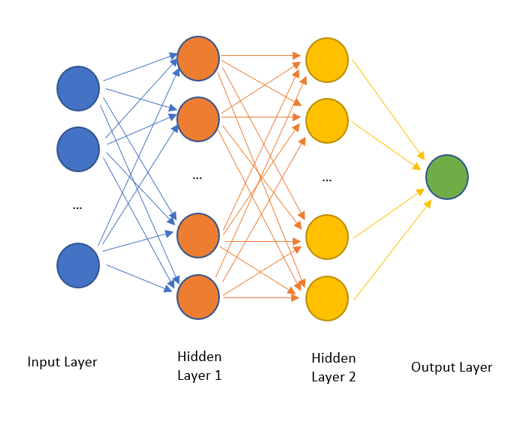
In words, we want to have these layers:

- Hidden layer 1: 12 neurons, ReLU activation
- Hidden layer 2: 16 neurons, ReLU activation
- Output Layer: 1 neuron, Sigmoid activation
    
Now, we need to describe this architecture to Keras. We will be using the Sequential model, which means that we merely need to describe the layers above in sequence.

In [12]:
# Dependencies
import keras
from keras.models import Sequential
from keras.layers import Dense

# define model

model = Sequential([
    Dense(12, activation='relu', input_shape=(10,)),
    Dense(16, activation='relu'),
    Dense(1, activation='sigmoid')
])

C:\Users\imane\miniconda3\Lib\site-packages\keras\src\layers\core\dense.py:100: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Now that the model is defined, we can compile it.

Compiling the model uses TensorFlow that chooses the best way to represent the network for training and making predictions to run on your hardware, such as CPU or GPU or even distributed.

In [13]:
# compile model
model.compile(loss='mean_squared_error', optimizer='sgd', metrics=['accuracy'])

We have defined our model and compiled it ready for efficient computation.

Now it is time to execute the model on some data (use 100 iterations and 32 batch size).

In [14]:
# train model
hist = model.fit(X_train, Y_train, epochs=100, batch_size=32)

Epoch 1/100
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5431 - loss: 0.2515
Epoch 2/100
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 993us/step - accuracy: 0.5773 - loss: 0.2452
Epoch 3/100
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 899us/step - accuracy: 0.6096 - loss: 0.2394
Epoch 4/100
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 889us/step - accuracy: 0.6399 - loss: 0.2342
Epoch 5/100
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 896us/step - accuracy: 0.6693 - loss: 0.2292
Epoch 6/100
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 871us/step - accuracy: 0.6888 - loss: 0.2243
Epoch 7/100
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 858us/step - accuracy: 0.7084 - loss: 0.2196
Epoch 8/100
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 853us/step - accuracy: 0.7211 - loss: 0.2150
Epoch 9/100
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7299 - loss: 0.2105 
Epoch 10/100
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 873us/step - accuracy: 0.7417 - loss: 0.2060
Epoch 11/100
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 838us/step - accuracy: 0.7524 - loss: 0.2016
Epoch 12/100
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 1

In [15]:
# predict on validation set
y_val_pred = (model.predict(X_val) > 0.5).astype(int)

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 


In [16]:
# calculate accuracy on validation set
from sklearn.metrics import accuracy_score
val_accuracy = accuracy_score(Y_val, y_val_pred)
print(f"Précision sur la validation : {val_accuracy}")

Précision sur la validation : 0.9269406392694064


We have trained our model, which gives us a correct accuracy. But we haven't used our validation set properly, and our test set at all. Let's correct that.

In [17]:
# train model
history = model.fit(X_train, Y_train, epochs=100, batch_size=32, validation_data=(X_val, Y_val))

Epoch 1/100
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8894 - loss: 0.0770 - val_accuracy: 0.9269 - val_loss: 0.0572
Epoch 2/100
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8904 - loss: 0.0769 - val_accuracy: 0.9269 - val_loss: 0.0570
Epoch 3/100
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8914 - loss: 0.0768 - val_accuracy: 0.9269 - val_loss: 0.0569
Epoch 4/100
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8914 - loss: 0.0767 - val_accuracy: 0.9269 - val_loss: 0.0568
Epoch 5/100
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8943 - loss: 0.0765 - val_accuracy: 0.9269 - val_loss: 0.0567
Epoch 6/100
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8943 - loss: 0.0764 - val_accuracy: 0.9269 - val_loss: 0.0565
Epoch 7/100
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8933 - loss: 0.0763 - val_accuracy: 0.9269 - val_loss: 0.0564
Epoch 8/100
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8933 - loss: 0.0762 - val_accuracy: 0.9269 - v

In [18]:
# predict on TEST set
y_test_pred = (model.predict(X_test) > 0.5).astype(int)

# calculate accuracy on test set
test_accuracy = accuracy_score(Y_test, y_test_pred)
print(f"Précision sur le test : {test_accuracy}")


7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
Précision sur le test : 0.9041095890410958


Visualize training and validation losses and accuracies plots with the help of keras

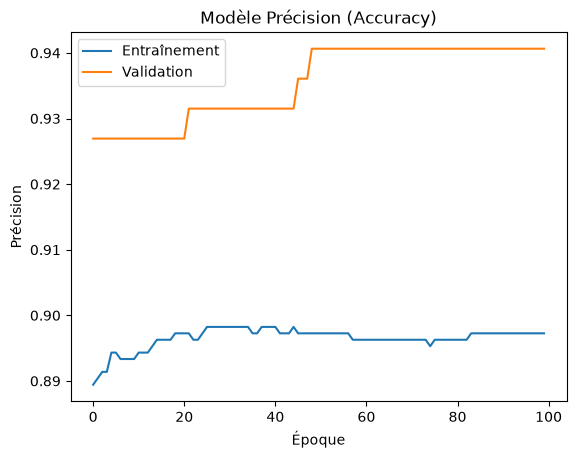

In [21]:
# visualize training and validation accuracies
import matplotlib.pyplot as plt


plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('Modèle Précision (Accuracy)')
plt.ylabel('Précision')
plt.xlabel('Époque')
plt.legend(['Entraînement', 'Validation'], loc='upper left')
plt.show()

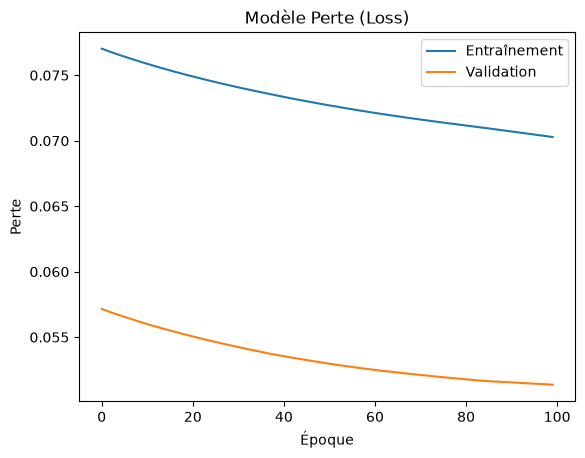

In [22]:
# visualize training and validation losses
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Modèle Perte (Loss)')
plt.ylabel('Perte')
plt.xlabel('Époque')
plt.legend(['Entraînement', 'Validation'], loc='upper right')
plt.show()

We have trained our neural network on the entire dataset and we can evaluate the performance of the network on the same dataset. A list of most hyperparameters available keras: 

https://keras.io/api/layers/initializers/

https://keras.io/api/layers/activations/

https://keras.io/api/losses/

https://keras.io/api/optimizers/